# Лабораторная работа 2. Решающие деревья, ансамбли

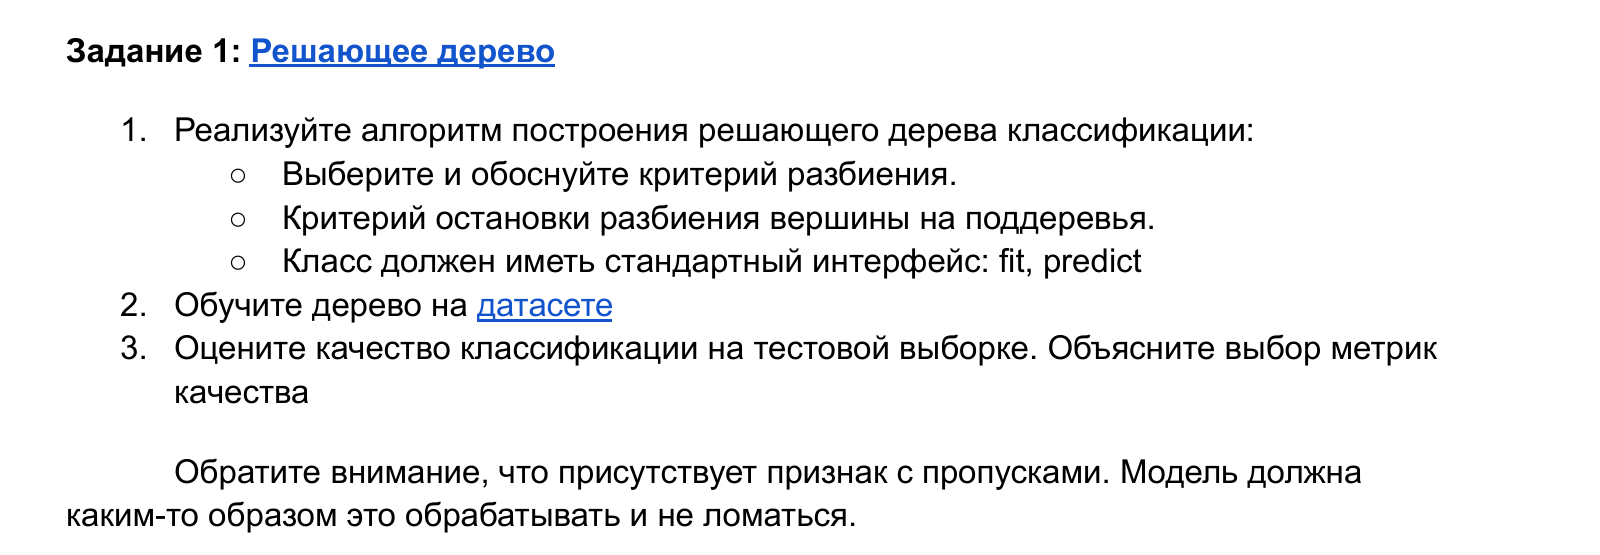

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

# датасет из условия (uci mushroom), файл лежит рядом с ноутбуком
columns = ['poisonous', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment',
           'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root',
           'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring',
           'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type',
           'spore-print-color', 'population', 'habitat']
df = pd.read_csv('agaricus-lepiota.data', header=None, names=columns, na_values='?')  # пропуски в файле записаны как ?

print(df.shape)  # строк, столбцов
df.head()

(8124, 23)


,poisonous,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [2]:
# обратите внимание, что присутствует признак с пропусками
print(df.isnull().sum()[lambda s: s > 0])  # только столбцы, где есть пропуски
df['poisonous'].value_counts()  # e -- съедобный, p -- ядовитый

stalk-root    2480
dtype: int64


poisonous
e    4208
p    3916
Name: count, dtype: int64

- 8124 гриба, 22 признака, все признаки -- буквы (категории), не числа
- пропуски только в `stalk-root`: 2480 штук
- классов почти поровну: 4208 съедобных (e) и 3916 ядовитых (p)

**расшифровка признаков:**

- poisonous -- класс гриба (то, что угадываем): e = съедобный, p = ядовитый
- cap-shape -- форма шляпки: b = колокол, c = конус, x = выпуклая, f = плоская, k = с бугорком, s = вогнутая
- cap-surface -- поверхность шляпки: f = волокнистая, g = с бороздками, y = чешуйчатая, s = гладкая
- cap-color -- цвет шляпки: n = коричневый, b = бежевый, c = корица, g = серый, r = зелёный, p = розовый, u = фиолетовый, e = красный, w = белый, y = жёлтый
- bruises -- есть ли синяки (пятна при надавливании): t = да, f = нет
- odor -- запах: a = миндаль, l = анис, c = креозот, y = рыбный, f = гнилой, m = затхлый, n = нет запаха, p = едкий, s = пряный
- gill-attachment -- как крепятся пластинки под шляпкой: a = приросшие, d = нисходящие, f = свободные, n = с выемкой
- gill-spacing -- расстояние между пластинками: c = близкие, w = частые, d = далёкие
- gill-size -- размер пластинок: b = широкие, n = узкие
- gill-color -- цвет пластинок: k = чёрный, n = коричневый, b = бежевый, h = шоколадный, g = серый, r = зелёный, o = оранжевый, p = розовый, u = фиолетовый, e = красный, w = белый, y = жёлтый
- stalk-shape -- форма ножки: e = расширяется, t = сужается
- stalk-root -- корень ножки: b = клубневидный, c = булава, u = чашеобразный, e = равный, z = ризоморфы, r = укоренённый (здесь пропуски)
- stalk-surface-above-ring -- поверхность ножки над кольцом: f = волокнистая, y = чешуйчатая, k = шелковистая, s = гладкая
- stalk-surface-below-ring -- поверхность ножки под кольцом: те же значения
- stalk-color-above-ring -- цвет ножки над кольцом: n = коричневый, b = бежевый, c = корица, g = серый, o = оранжевый, p = розовый, e = красный, w = белый, y = жёлтый
- stalk-color-below-ring -- цвет ножки под кольцом: те же значения
- veil-type -- тип покрывала: p = частичное, u = полное
- veil-color -- цвет покрывала: n = коричневый, o = оранжевый, w = белый, y = жёлтый
- ring-number -- число колец: n = нет, o = одно, t = два
- ring-type -- тип кольца: c = паутинистое, e = исчезающее, f = расширяющееся, l = большое, n = нет, p = висячее, s = обволакивающее, z = зональное
- spore-print-color -- цвет споровой массы: k = чёрный, n = коричневый, b = бежевый, h = шоколадный, r = зелёный, o = оранжевый, u = фиолетовый, w = белый, y = жёлтый
- population -- как растут: a = обильно, c = группами, n = многочисленно, s = разбросанно, v = несколько, y = по одному
- habitat -- где растут: g = трава, l = листья, m = луга, p = тропинки, u = город, w = пустырь, d = лес

In [3]:
from sklearn.model_selection import train_test_split

# делим на train и test (80/20), stratify -- чтобы доли классов в обеих частях были одинаковые
X = df.drop(columns='poisonous')
y = df['poisonous']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(6499, 22) (1625, 22)


**что такое решающее дерево:**

- дерево задаёт цепочку вопросов про объект, например "запах входит в набор {миндаль, анис, нет запаха}?"
- по ответам да / нет идём вниз, пока не дойдём до листа
- в листе записан ответ -- тот класс, которого больше среди обучающих объектов этого листа
- обучение -- это выбор вопроса для каждого узла так, чтобы после деления в каждой части оставался в основном один класс

**критерий разбиения: Gini и выигрыш**

- Gini показывает, насколько узел "перемешан" по классам:

$$G = 1 - \sum_k p_k^2$$

- $p_k$ -- доля объектов класса $k$ в узле. $G = 0$ -- в узле один класс, для двух классов максимум 0.5 (классов поровну)
- выигрыш от деления узла на левую и правую части:

$$Q = G(\text{узел}) - \frac{n_L}{n}G(\text{левая}) - \frac{n_R}{n}G(\text{правая})$$

- $n$ -- число объектов в узле, $n_L$ и $n_R$ -- сколько попало влево и вправо. $Q$ показывает, насколько деление сделало части чище
- перебираем разбиения и берём то, где $Q$ максимальный
- почему Gini: формула простая, без логарифмов (в отличие от энтропии), и это значение по умолчанию у sklearn

**как делим по признакам-буквам:**

- вопрос в узле: "значение признака входит в набор?"
- перебирать все наборы значений долго, поэтому значения сортируем по доле ядовитых и режем как по числовой оси: слева первые несколько значений, справа остальные. для двух классов так находится лучшее разбиение из всех возможных (так написано в статье из условия)
- значение, которого не было в обучении, уходит в правую ветку

**критерии остановки (узел становится листом):**

- в узле один класс -- делить нечего
- дошли до максимальной глубины (у нас 4) -- чтобы дерево не разрасталось, не запоминало обучающую выборку и его можно было прочитать
- все объекты в узле одинаковые по признакам -- разделить нечем

**пропуски:**

- пропуск считаем ещё одним значением признака -- `пропуск`, как будто это ещё одна буква
- дерево само решает, полезно ли про него спрашивать, поэтому ничего удалять и подставлять не нужно, и модель не ломается

In [ ]:
# реализуйте алгоритм построения решающего дерева классификации:
# критерий разбиения, критерий остановки, интерфейс fit / predict

from dataclasses import dataclass
from typing import Optional


def to_string_matrix(X) -> np.ndarray:
    """таблицу признаков превращает в numpy-матрицу строк (строка -- объект, столбец -- признак)

    пример: [['x', nan], ['b', 'c']] -> [['x', 'пропуск'], ['b', 'c']]
    """
    # шаг 1. таблицу pandas превращаем в обычную numpy-матрицу
    if isinstance(X, pd.DataFrame):
        X = X.to_numpy(dtype=object)
    X = np.asarray(X)

    # шаг 2. если это уже матрица строк (dtype.kind == 'U' -- строки), больше ничего делать не нужно
    if X.dtype.kind == 'U':
        return X

    # шаг 3. пропуски (NaN) заменяем на 'пропуск', всё остальное переводим в строки
    return np.where(pd.isna(X), 'пропуск', X).astype(str)


def gini(class_weights: np.ndarray) -> np.ndarray:
    """нечистота Gini: 1 - сумма (доля класса)^2. 0 -- в узле один класс

    class_weights -- сколько объектов каждого класса, например [3, 1] = 3 съедобных и 1 ядовитый
    (на самом деле это сумма весов объектов, см. fit; если у всех вес 1, то просто число объектов).
    можно передать и матрицу: каждая строка -- отдельный узел, тогда вернётся по одному числу на строку

    пример: [3, 1] -> доли [0.75, 0.25] -> 1 - 0.5625 - 0.0625 = 0.375
    """
    # шаг 1. сколько всего объектов (axis=-1 -- сумма по последней оси, то есть по классам)
    total = class_weights.sum(axis=-1)

    # шаг 2. доли классов. [..., None] добавляет ось, чтобы поделить каждую строку на её сумму,
    # max нужен, чтобы не делить на ноль в пустом узле
    shares = class_weights / np.maximum(total, 1e-12)[..., None]

    # шаг 3. 1 - сумма квадратов долей
    return 1 - (shares ** 2).sum(axis=-1)


@dataclass
class Node:
    """узел дерева. лист -- это узел без детей (left и right равны None)"""
    class_weights: np.ndarray                  # вес объектов каждого класса в узле, например [3374., 6.] (порядок классов как в classes_)
    feature: Optional[int] = None              # номер признака (столбца), про который узел задаёт вопрос. у листа None
    left_values: Optional[np.ndarray] = None   # значения признака, которые идут в левую ветку ("да"). в правую идут все остальные
    left: Optional['Node'] = None              # левый ребёнок
    right: Optional['Node'] = None             # правый ребёнок


class MyDecisionTree:
    def __init__(self, max_depth: Optional[int] = None, max_features: Optional[int] = None,
                 random_state: Optional[int] = None):
        # настройки, задаются при создании дерева
        self.max_depth = max_depth          # максимальная глубина дерева (None -- без ограничения)
        self.max_features = max_features    # из скольких случайных признаков выбираем лучший вопрос в узле (None -- из всех)
                                            # сам вопрос всегда про один признак
        self.random_state = random_state    # число для генератора случайных чисел, чтобы результат повторялся

        # поля, которые заполняются в fit
        self.classes_: Optional[np.ndarray] = None       # названия классов по порядку, например ['e', 'p']
        self.n_classes_: int = 0                         # сколько всего классов (у нас 2)
        self.categories_: list = []                      # для каждого признака -- список его значений, например у запаха ['a', 'c', 'f', ...]
        self.rng_: Optional[np.random.Generator] = None  # генератор случайных чисел
        self.root_: Optional[Node] = None                # корень дерева

    def fit(self, X, y, sample_weight=None) -> 'MyDecisionTree':
        """обучение: строит дерево по обучающим данным

        X -- таблица признаков (строка -- объект), 
        y -- правильные ответы (класс каждого объекта)
        sample_weight -- вес каждого объекта, то есть насколько он важен (по умолчанию у всех 1).
        """
        # шаг 1. приводим признаки к матрице строк
        X = to_string_matrix(X)
        n_objects, n_features = X.shape

        # шаг 2. классы: названия сохраняем в classes_, а ответы переводим в номера (class_ids)
        # пример: y = ['p', 'e', 'p'] -> classes_ = ['e', 'p'], class_ids = [1, 0, 1]
        self.classes_, class_ids = np.unique(np.asarray(y), return_inverse=True)
        self.n_classes_ = len(self.classes_)

        # шаг 3. веса объектов
        weights = np.ones(n_objects) if sample_weight is None else np.asarray(sample_weight, dtype=float)

        # шаг 4. значения каждого признака переводим в числа 0, 1, 2...
        # пример: у запаха categories_ = ['a', 'c', 'f'], значение 'f' получает код 2
        # value_codes[i, j] -- код значения признака j у объекта i
        self.categories_ = []
        value_codes = np.empty((n_objects, n_features), dtype=int)
        for feature in range(n_features):
            categories, value_codes[:, feature] = np.unique(X[:, feature], return_inverse=True)
            self.categories_.append(categories)

        # шаг 5. растим дерево от корня, в корень попадают все объекты
        self.rng_ = np.random.default_rng(self.random_state)
        self.root_ = self._build_node(value_codes, class_ids, weights, np.arange(n_objects), depth=0)
        return self

    def _build_node(self, value_codes, class_ids, weights, object_ids, depth: int) -> Node:
        """строит узел для объектов object_ids (номера строк обучающей выборки)
        для детей вызывает сам себя, поэтому строит сразу всё поддерево. depth -- глубина узла (корень -- 0)"""
        # шаг 1. вес каждого класса среди объектов узла, например [3374., 6.]
        # bincount считает, сколько раз встретился каждый номер класса (с учётом весов)
        class_weights = np.bincount(class_ids[object_ids], weights=weights[object_ids], minlength=self.n_classes_)
        node = Node(class_weights)

        # шаг 2. критерии остановки -- тогда узел остаётся листом
        is_pure = gini(class_weights) == 0                                          # в узле один класс
        is_max_depth = self.max_depth is not None and depth >= self.max_depth       # дошли до максимальной глубины
        if is_pure or is_max_depth:
            return node

        # шаг 3. ищем лучший вопрос для узла
        best = self._find_best_split(value_codes, class_ids, weights, object_ids, class_weights)
        if best is None:  # делить нечем: объекты одинаковые по всем признакам
            return node

        # шаг 4. делим объекты узла: кто отвечает "да" (значение в левом наборе) идёт влево, остальные вправо
        feature, left_codes = best
        goes_left = np.isin(value_codes[object_ids, feature], left_codes)  # True / False для каждого объекта узла
        node.feature = feature
        node.left_values = self.categories_[feature][left_codes]

        # шаг 5. строим детей
        node.left = self._build_node(value_codes, class_ids, weights, object_ids[goes_left], depth + 1)
        node.right = self._build_node(value_codes, class_ids, weights, object_ids[~goes_left], depth + 1)
        return node

    def _find_best_split(self, value_codes, class_ids, weights, object_ids, node_class_weights):
        """ищет лучший вопрос для узла: "значение признака входит в набор?"
        возвращает (номер признака, коды значений для левой ветки) или None, если разделить нечем"""
        # шаг 1. подготовка
        n_features = value_codes.shape[1]
        n_to_check = n_features if self.max_features is None else self.max_features  # сколько признаков проверить
        node_impurity = gini(node_class_weights)   # нечистота узла до деления
        node_weight = node_class_weights.sum()     # общий вес объектов узла
        # порядок проверки: по порядку, а если смотрим не все признаки -- в случайном
        feature_order = np.arange(n_features) if self.max_features is None else self.rng_.permutation(n_features)

        # данные только по объектам узла
        node_codes = value_codes[object_ids]
        node_class_ids = class_ids[object_ids]
        node_weights = weights[object_ids]

        best_gain, best = -1.0, None
        n_checked = 0
        for feature in feature_order:
            if n_checked >= n_to_check and best is not None:
                break

            # шаг 2. таблица "значение признака x класс": weight_table[v, c] -- вес объектов класса c, у которых значение v
            n_values = len(self.categories_[feature])
            weight_table = np.zeros((n_values, self.n_classes_))
            for class_id in range(self.n_classes_):
                in_class = node_class_ids == class_id
                weight_table[:, class_id] = np.bincount(node_codes[in_class, feature], weights=node_weights[in_class],
                                                        minlength=n_values)

            # шаг 3. оставляем только значения, которые есть в узле
            value_is_in_node = weight_table.sum(axis=1) > 0
            if value_is_in_node.sum() < 2:  # значение одно -- по этому признаку не разделить
                continue
            n_checked += 1
            weight_table = weight_table[value_is_in_node]
            present_codes = np.flatnonzero(value_is_in_node)  # коды оставленных значений

            # шаг 4. значения сортируем по доле класса 1 (у нас ядовитые) и режем как по числовой оси
            # пример для запаха в узле:
            #   значение     вес e   вес p   доля p
            #   a (миндаль)   400      0      0
            #   n (нет)      3408    120      0.03
            #   f (гнилой)      0   2160      1
            # порядок a, n, f. разрезы: [a | n, f] и [a, n | f], выбираем лучший по выигрышу
            share_of_class_1 = weight_table[:, 1] / weight_table.sum(axis=1)
            order = np.argsort(share_of_class_1, kind='stable')

            # шаг 5. все разрезы: left_weights[i] -- вес каждого класса слева, если слева первые i+1 значений
            left_weights = np.cumsum(weight_table[order], axis=0)[:-1]
            right_weights = node_class_weights - left_weights

            # шаг 6. выигрыш Q каждого разреза: нечистота узла минус нечистота частей, взвешенная по их размеру
            gain = node_impurity - (left_weights.sum(axis=1) * gini(left_weights)
                                    + right_weights.sum(axis=1) * gini(right_weights)) / node_weight

            # шаг 7. запоминаем лучший разрез, если он лучше всех прошлых
            best_cut = np.argmax(gain)
            if gain[best_cut] > best_gain:
                best_gain = gain[best_cut]
                best = (feature, present_codes[order[:best_cut + 1]])
        return best

    def predict(self, X) -> np.ndarray:
        """ответ дерева для каждого объекта: массив классов, например ['e', 'p', 'e']"""
        X = to_string_matrix(X)
        answers = np.zeros(len(X), dtype=int)  # сюда запишем номера классов
        self._predict_node(self.root_, X, np.arange(len(X)), answers)
        return self.classes_[answers]          # номера классов -> названия

    def _predict_node(self, node: Node, X, object_ids, answers):
        """проводит объекты object_ids через узел. в листе записывает ответ, иначе делит на левых и правых
        и отправляет в детей"""
        # шаг 1. объектов не осталось -- выходим
        if len(object_ids) == 0:
            return

        # шаг 2. лист: ответ -- самый тяжёлый класс (argmax -- номер наибольшего элемента)
        if node.left is None:
            answers[object_ids] = np.argmax(node.class_weights)
            return

        # шаг 3. вопрос узла: значение нужного признака входит в left_values? (isin -- True, если входит)
        # незнакомое значение, которого не было в обучении, не входит ни в какой набор и уйдёт вправо
        goes_left = np.isin(X[object_ids, node.feature], node.left_values)

        # шаг 4. левых отправляем в левого ребёнка, остальных в правого
        self._predict_node(node.left, X, object_ids[goes_left], answers)
        self._predict_node(node.right, X, object_ids[~goes_left], answers)

    def export_text(self, feature_names) -> str:
        """дерево в виде правил, чтобы его можно было прочитать глазами
        в листе: класс-ответ и в скобках, сколько объектов каждого класса попало в этот лист при обучении"""
        lines = []

        def walk(node: Node, depth: int):
            indent = '    ' * depth
            if node.left is None:  # лист
                answer = self.classes_[np.argmax(node.class_weights)]
                per_class = ', '.join(f"{name}: {weight:g}" for name, weight in zip(self.classes_, node.class_weights))
                lines.append(f"{indent}класс {answer} ({per_class})")
                return
            values = ', '.join(sorted(node.left_values))
            lines.append(f"{indent}если {feature_names[node.feature]} in [{values}]:")
            walk(node.left, depth + 1)
            lines.append(f"{indent}иначе:")
            walk(node.right, depth + 1)

        walk(self.root_, 0)
        return '\n'.join(lines)

In [5]:
# обучите дерево на датасете
t0 = time.perf_counter()
tree = MyDecisionTree(max_depth=4).fit(X_train, y_train)
tree_time = time.perf_counter() - t0

tree_pred = tree.predict(X_test)
print(tree.export_text(X.columns))

если odor in [a, l, n]:
    если spore-print-color in [b, h, k, n, o, u, w, y]:
        если stalk-color-below-ring in [e, g, n, o, p, w]:
            если cap-surface in [f, s, y]:
                класс e (e: 3366, p: 14)
            иначе:
                класс p (e: 0, p: 3)
        иначе:
            класс p (e: 0, p: 19)
    иначе:
        класс p (e: 0, p: 61)
иначе:
    класс p (e: 0, p: 3036)


как читать: идём сверху вниз, `если` -- ответ да, `иначе` -- ответ нет. в конце стоит класс гриба, а в скобках -- сколько объектов каждого класса из train попало в этот лист

- первый вопрос про запах (`odor`): миндаль, анис или нет запаха -- идём дальше, любой другой запах -- сразу ядовитый (в этом листе 3036 ядовитых и ни одного съедобного)
- дальше вопросы про цвет споровой массы, цвет ножки под кольцом и поверхность шляпки
- съедобным гриб считается, только если на все четыре вопроса ответ "да". в этом листе 3366 съедобных и 14 ядовитых -- из-за них дерево ошибается

**какие метрики и почему:**

- классов почти поровну, поэтому accuracy (доля верных ответов) честно показывает качество
- ошибки не равны по цене: принять ядовитый гриб за съедобный опаснее, чем наоборот. поэтому главная метрика -- recall по ядовитым (какую долю ядовитых нашли)
- precision по ядовитым -- какая доля ответов "ядовитый" верная (ошибка здесь -- выбросили съедобный гриб)
- F1 -- одно число из precision и recall
- матрица ошибок показывает, какие именно ошибки делает модель

In [6]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from IPython.display import display

def evaluate(y_true, y_pred):
    # ядовитый (p) считаем "положительным" классом
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'recall (ядовитые)': recall_score(y_true, y_pred, pos_label='p'),
        'precision (ядовитые)': precision_score(y_true, y_pred, pos_label='p'),
        'F1 (ядовитые)': f1_score(y_true, y_pred, pos_label='p'),
        'ошибок': int((np.asarray(y_true) != y_pred).sum()),
    }

# оцените качество классификации на тестовой выборке
res = evaluate(y_test, tree_pred)
metric_table = pd.DataFrame({
    'показатель': ['accuracy', 'recall (ядовитые)', 'precision (ядовитые)', 'F1 (ядовитые)'],
    'что означает': [
        'доля верных ответов',
        'какую долю ядовитых грибов нашли',
        'какая доля ответов "ядовитый" верная',
        'одно число из precision и recall',
    ],
})
metric_table['значение'] = [res['accuracy'], res['recall (ядовитые)'], res['precision (ядовитые)'], res['F1 (ядовитые)']]

display(metric_table.round(4))
confusion_matrix_table = pd.DataFrame(confusion_matrix(y_test, tree_pred, labels=['e', 'p']),
                                      index=['на самом деле e', 'на самом деле p'],
                                      columns=['ответ e', 'ответ p'])
confusion_matrix_table

,показатель,что означает,значение
0,accuracy,доля верных ответов,0.9963
1,recall (ядовитые),какую долю ядовитых грибов нашли,0.9923
2,precision (ядовитые),"какая доля ответов ""ядовитый"" верная",1.0000
3,F1 (ядовитые),одно число из precision и recall,0.9962


,ответ e,ответ p
на самом деле e,842,0
на самом деле p,6,777


- accuracy 0.9963: из 1625 грибов неверно угадано 6
- recall по ядовитым 0.9923: нашли 777 ядовитых из 783, 6 пропустили
- precision по ядовитым 1.0: съедобных грибов ядовитыми не назвали ни разу
- все 6 ошибок одного типа -- ядовитый гриб принят за съедобный

In [7]:
# модель не ломается на признаке с пропусками
missing_test = X_test['stalk-root'].isnull().to_numpy()
print('объектов с пропуском в test:', missing_test.sum())
print('accuracy на них:', round(accuracy_score(y_test[missing_test], tree_pred[missing_test]), 4))

объектов с пропуском в test: 512
accuracy на них: 0.9922


- в test 512 грибов с пропуском в `stalk-root`, на них accuracy 0.9922
- пропуск обрабатывается как обычное значение, модель не ломается

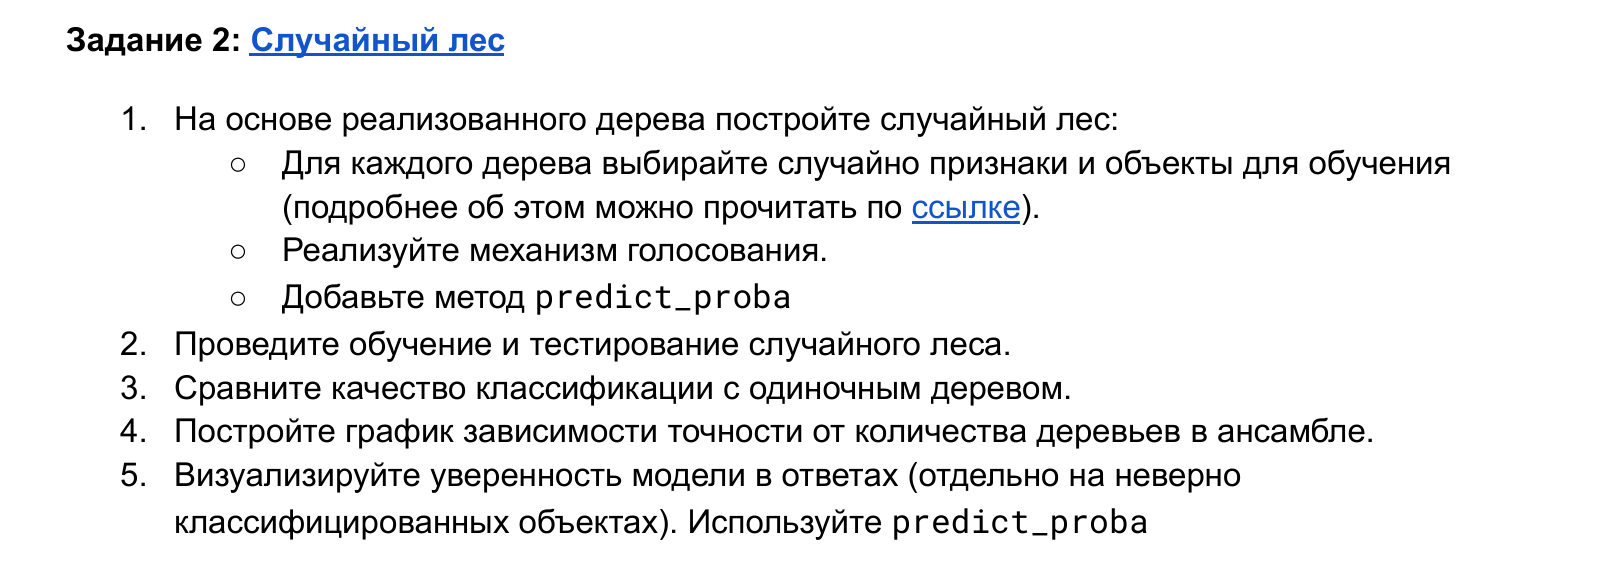

**что такое случайный лес:**

- лес -- это много деревьев, ответ получается голосованием
- чтобы деревья получились разные, каждому дают случайности:
    - свои объекты: берём из train столько же объектов, но случайно **с возвращением** (бутстреп), поэтому часть объектов повторяется, а часть не попадает
    - свои признаки: в каждой вершине дерево смотрит не все 22 признака, а случайные 4 (корень из 22, так по умолчанию делает sklearn)
- голосование: каждое дерево называет класс, побеждает тот, за которого проголосовало больше деревьев
- `predict_proba` -- доля деревьев, проголосовавших за каждый класс (0.9 значит 90 деревьев из 100)

In [8]:
# на основе реализованного дерева постройте случайный лес:
# случайные признаки и объекты для каждого дерева, голосование, predict_proba

class MyRandomForest:
    def __init__(self, n_trees: int = 100, max_depth: Optional[int] = None, max_features='sqrt',
                 random_state: Optional[int] = None):
        # настройки, задаются при создании леса
        self.n_trees = n_trees              # сколько деревьев в лесу
        self.max_depth = max_depth          # максимальная глубина каждого дерева
        self.max_features = max_features    # сколько признаков смотреть в вершине: 'sqrt' -- корень из числа признаков
        self.random_state = random_state    # для повторяемости результата

        # поля, которые заполняются в fit
        self.classes_: Optional[np.ndarray] = None  # названия классов по порядку, например ['e', 'p']
        self.trees_: list = []                      # обученные деревья (список MyDecisionTree)

    def fit(self, X, y) -> 'MyRandomForest':
        """обучение: строит n_trees деревьев, каждое на своей случайной выборке объектов"""
        # шаг 1. приводим данные к удобному виду
        X = to_string_matrix(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        n_objects, n_features = X.shape

        # шаг 2. сколько признаков каждое дерево смотрит в каждой вершине
        n_features_per_split = int(np.sqrt(n_features)) if self.max_features == 'sqrt' else n_features
        rng = np.random.default_rng(self.random_state)

        # шаг 3. строим деревья
        self.trees_ = []
        for _ in range(self.n_trees):
            # бутстреп: берём n_objects номеров объектов случайно с возвращением,
            # поэтому часть объектов повторяется, а часть не попадает в выборку дерева
            bootstrap_ids = rng.integers(0, n_objects, n_objects)
            tree = MyDecisionTree(self.max_depth, max_features=n_features_per_split,
                                  random_state=int(rng.integers(1_000_000_000)))
            tree.fit(X[bootstrap_ids], y[bootstrap_ids])
            self.trees_.append(tree)
        return self

    def tree_votes(self, X) -> np.ndarray:
        """ответ каждого дерева: матрица (деревьев x объектов), в ячейке номер класса (0 или 1), который назвало дерево"""
        X = to_string_matrix(X)
        return np.array([np.searchsorted(self.classes_, tree.predict(X)) for tree in self.trees_])

    def predict_proba(self, X) -> np.ndarray:
        """доля деревьев, проголосовавших за каждый класс: матрица (объектов x классов), в каждой строке сумма 1
        пример: [0.19, 0.81] -- 19 деревьев из 100 за класс 0, 81 за класс 1"""
        votes = self.tree_votes(X)
        return np.stack([(votes == class_id).mean(axis=0) for class_id in range(len(self.classes_))], axis=1)

    def predict(self, X) -> np.ndarray:
        """голосование: ответ леса -- класс, за который проголосовало больше деревьев"""
        return self.classes_[self.predict_proba(X).argmax(axis=1)]

In [9]:
# проведите обучение и тестирование случайного леса
t0 = time.perf_counter()
forest = MyRandomForest(n_trees=100, max_depth=4, random_state=42).fit(X_train, y_train)
forest_time = time.perf_counter() - t0

forest_pred = forest.predict(X_test)
forest_proba = forest.predict_proba(X_test)

print('классы:', forest.classes_)  # порядок столбцов в predict_proba
forest_proba[:5].round(2)  # первые 5 объектов теста

классы: ['e' 'p']


array([[0.  , 1.  ],
       [0.19, 0.81],
       [0.99, 0.01],
       [0.  , 1.  ],
       [0.  , 1.  ]])

- каждая строка -- один гриб, в ней доли деревьев, проголосовавших за `e` и за `p` (в сумме 1)
- например, у второго гриба 0.19 за `e` и 0.81 за `p`: 81 дерево из 100 назвало его ядовитым

In [10]:
# сравните качество классификации с одиночным деревом
pd.DataFrame({
    'одно дерево': evaluate(y_test, tree_pred),
    'лес (100 деревьев)': evaluate(y_test, forest_pred),
}).T

,accuracy,recall (ядовитые),precision (ядовитые),F1 (ядовитые),ошибок
одно дерево,0.996308,0.992337,1.0,0.996154,6.0
лес (100 деревьев),0.998154,0.996169,1.0,0.998081,3.0


- лес: accuracy 0.9982 и 3 ошибки, одно дерево: 0.9963 и 6 ошибок -- лес ошибается вдвое реже
- recall по ядовитым вырос с 0.9923 до 0.9962 (пропущено 3 ядовитых вместо 6)
- precision у обоих 1.0

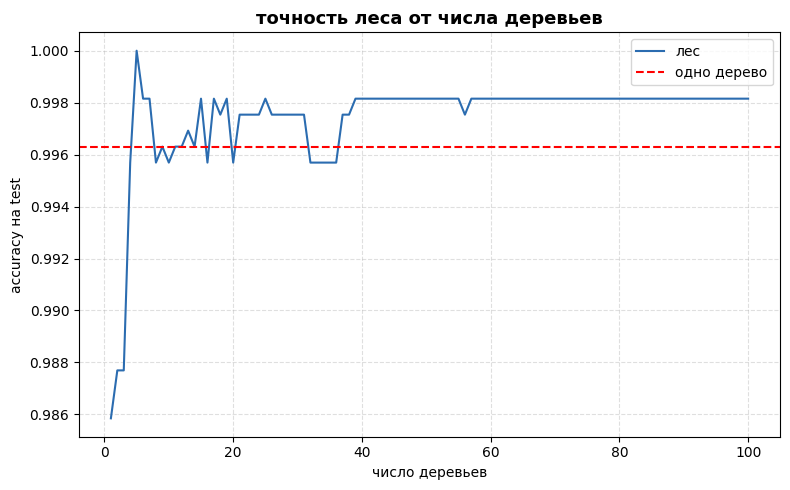

In [11]:
# постройте график зависимости точности от количества деревьев в ансамбле
votes = forest.tree_votes(X_test)
y_test_num = np.searchsorted(forest.classes_, y_test)  # классы в виде 0 / 1

# голосуем только первыми k деревьями
acc_by_trees = [((votes[:k].mean(axis=0) > 0.5).astype(int) == y_test_num).mean() for k in range(1, 101)]

plt.figure(figsize=(8, 5))
plt.plot(range(1, 101), acc_by_trees, color='#2b6cb0', label='лес')
plt.axhline(accuracy_score(y_test, tree_pred), color='red', linestyle='--', label='одно дерево')
plt.title('точность леса от числа деревьев', fontsize=13, fontweight='bold')
plt.xlabel('число деревьев')
plt.ylabel('accuracy на test')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

- с одним деревом accuracy 0.9858 -- ниже, чем у обычного дерева, потому что оно в каждой вершине видит только 4 случайных признака и учится на части объектов
- примерно до 36 деревьев график скачет вокруг линии одного дерева, после -- выше неё
- с 57 деревьев accuracy не меняется (0.9982), новые деревья уже ничего не добавляют

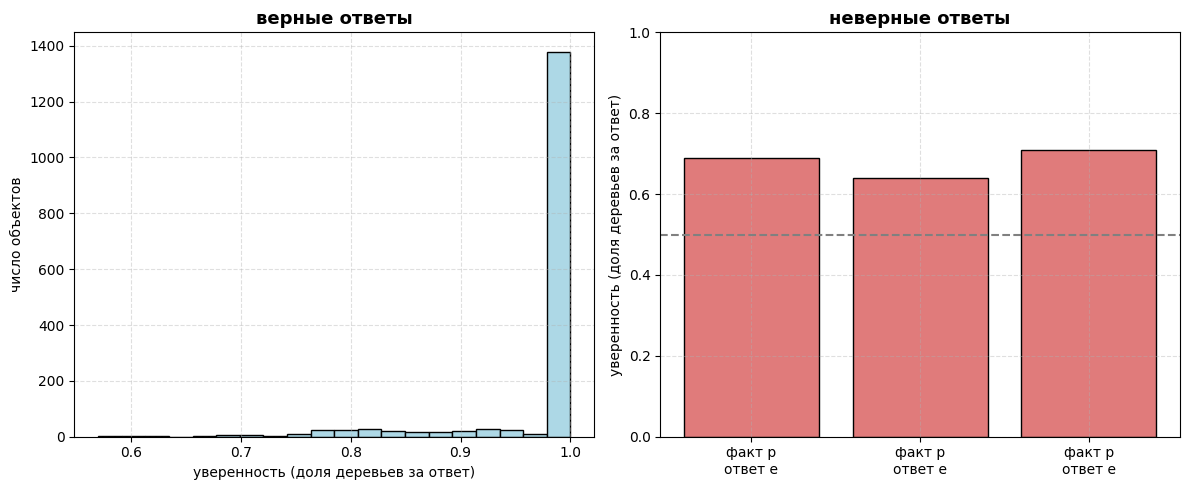

In [12]:
# визуализируйте уверенность модели в ответах (отдельно на неверно классифицированных), используйте predict_proba
confidence = forest_proba.max(axis=1)  # доля деревьев, которые проголосовали за выбранный класс
wrong = forest_pred != y_test.to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(confidence[~wrong], bins=20, edgecolor='black', color='#add8e6')
axes[0].set_title('верные ответы', fontsize=13, fontweight='bold')
axes[0].set_xlabel('уверенность (доля деревьев за ответ)')
axes[0].set_ylabel('число объектов')
axes[0].grid(True, linestyle='--', alpha=0.4)

labels = [f'факт {t}\nответ {p}' for t, p in zip(y_test.to_numpy()[wrong], forest_pred[wrong])]
axes[1].bar(range(wrong.sum()), confidence[wrong], color='#e07b7b', edgecolor='black')
axes[1].set_xticks(range(wrong.sum()))
axes[1].set_xticklabels(labels)
axes[1].axhline(0.5, color='gray', linestyle='--')
axes[1].set_ylim(0, 1)
axes[1].set_title('неверные ответы', fontsize=13, fontweight='bold')
axes[1].set_ylabel('уверенность (доля деревьев за ответ)')
axes[1].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

- верные ответы (1622): у 1138 уверенность 1.0, то есть все 100 деревьев согласны, у 1459 -- не ниже 0.9
- неверные ответы (3): уверенность 0.64, 0.69 и 0.71 -- за неверный ответ было 64-71 дерево из 100
- во всех трёх ошибках ядовитый гриб принят за съедобный

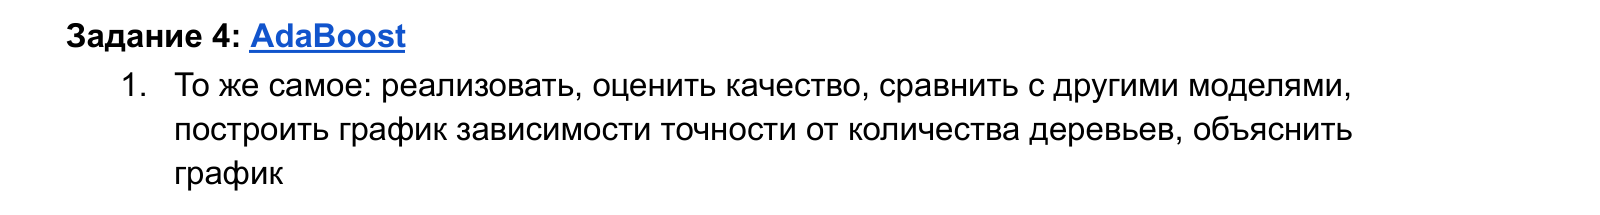

**что такое AdaBoost:**

- деревья строятся по очереди (а не независимо, как в лесу), и каждое следующее старается исправить ошибки предыдущих
- у каждого объекта есть вес, сначала у всех одинаковый. дерево учится с учётом весов: ошибка на тяжёлом объекте "дороже"
- после каждого дерева веса объектов, на которых оно ошиблось, растут, а у угаданных падают. следующее дерево сильнее смотрит на трудные объекты
- у каждого дерева свой вес голоса $\alpha$: чем меньше ошибка дерева, тем он больше

$$\varepsilon = \sum_i w_i \cdot [\text{дерево ошиблось на объекте } i], \qquad \alpha = \frac{1}{2}\ln\frac{1-\varepsilon}{\varepsilon}$$

- новые веса объектов ($y_i$ -- настоящий ответ, $h(x_i)$ -- ответ дерева, оба равны -1 или +1; $Z$ делает сумму весов равной 1):

$$w_i \leftarrow \frac{w_i \, e^{-\alpha \, y_i \, h(x_i)}}{Z}$$

- итоговый ответ -- голосование деревьев с весами:

$$H(x) = \text{sign}\left(\sum_t \alpha_t \, h_t(x)\right)$$

- деревья берём совсем простые: пни (глубина 1, один вопрос)

In [13]:
# реализовать adaboost
class MyAdaBoost:
    def __init__(self, n_estimators: int = 50, max_depth: int = 1):
        # настройки, задаются при создании
        self.n_estimators = n_estimators   # сколько деревьев построить (максимум)
        self.max_depth = max_depth         # глубина каждого дерева (1 -- пень, один вопрос)

        # поля, которые заполняются в fit
        self.classes_: Optional[np.ndarray] = None  # названия классов по порядку, например ['e', 'p']
        self.trees_: list = []                      # обученные деревья по порядку
        self.alphas_: list = []                     # вес голоса каждого дерева (alpha из формулы)

    def fit(self, X, y) -> 'MyAdaBoost':
        """обучение: деревья строятся по очереди, каждое следующее сильнее смотрит на объекты,
        на которых ошибались прошлые"""
        # шаг 1. подготовка
        X = to_string_matrix(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        true_signs = np.where(y == self.classes_[1], 1, -1)  # настоящие ответы в виде -1 / +1 (+1 -- второй класс)
        weights = np.full(len(y), 1 / len(y))                # вес каждого объекта, сначала все одинаково важны

        self.trees_, self.alphas_ = [], []
        for _ in range(self.n_estimators):
            # шаг 2. учим дерево с учётом весов объектов
            tree = MyDecisionTree(max_depth=self.max_depth).fit(X, y, sample_weight=weights)
            tree_signs = np.where(tree.predict(X) == self.classes_[1], 1, -1)  # ответы дерева в виде -1 / +1

            # шаг 3. ошибка дерева: сумма весов объектов, на которых оно ошиблось
            weighted_error = weights[tree_signs != true_signs].sum()
            if weighted_error >= 0.5:                      # дерево не лучше случайного -- стоп
                break
            weighted_error = max(weighted_error, 1e-10)    # чтобы не делить на ноль, если ошибок нет

            # шаг 4. вес голоса дерева: чем меньше ошибка, тем больше
            alpha = 0.5 * np.log((1 - weighted_error) / weighted_error)

            # шаг 5. новые веса объектов: на ошибках растут, на верных падают
            # потом делим на сумму, чтобы сумма весов снова была 1
            weights = weights * np.exp(-alpha * true_signs * tree_signs)
            weights = weights / weights.sum()

            self.trees_.append(tree)
            self.alphas_.append(alpha)
            if weighted_error <= 1e-10:                    # ошибок нет -- дальше учить нечего
                break
        return self

    def staged_predict(self, X) -> np.ndarray:
        """ответы ансамбля после 1, 2, 3... деревьев: матрица (деревьев x объектов) с названиями классов"""
        X = to_string_matrix(X)
        # голос каждого дерева: его ответ (-1 / +1), умноженный на вес голоса alpha
        votes = [alpha * np.where(tree.predict(X) == self.classes_[1], 1, -1)
                 for tree, alpha in zip(self.trees_, self.alphas_)]
        running_total = np.cumsum(votes, axis=0)  # сумма голосов первых 1, 2, 3... деревьев
        return np.where(running_total >= 0, self.classes_[1], self.classes_[0])

    def predict(self, X) -> np.ndarray:
        """итоговый ответ: голосование всех деревьев с весами"""
        return self.staged_predict(X)[-1]

In [14]:
# оценить качество
t0 = time.perf_counter()
ada = MyAdaBoost(n_estimators=100, max_depth=1).fit(X_train, y_train)
ada_time = time.perf_counter() - t0

ada_pred = ada.predict(X_test)
print('деревьев в ансамбле:', len(ada.trees_))
pd.DataFrame([evaluate(y_test, ada_pred)], index=['adaboost'])

деревьев в ансамбле: 100


,accuracy,recall (ядовитые),precision (ядовитые),F1 (ядовитые),ошибок
adaboost,1.0,1.0,1.0,1.0,0


- 100 деревьев-пней, на test accuracy 1.0 -- ошибок нет (0 из 1625)

In [15]:
# сравнить с другими моделями
pd.DataFrame({
    'одно дерево': evaluate(y_test, tree_pred),
    'лес (100 деревьев)': evaluate(y_test, forest_pred),
    'adaboost (100 пней)': evaluate(y_test, ada_pred),
}).T

,accuracy,recall (ядовитые),precision (ядовитые),F1 (ядовитые),ошибок
одно дерево,0.996308,0.992337,1.0,0.996154,6.0
лес (100 деревьев),0.998154,0.996169,1.0,0.998081,3.0
adaboost (100 пней),1.000000,1.000000,1.0,1.000000,0.0


- ошибок на test: adaboost 0, лес 3, одно дерево 6
- adaboost точнее всех, хотя каждое его дерево задаёт всего один вопрос

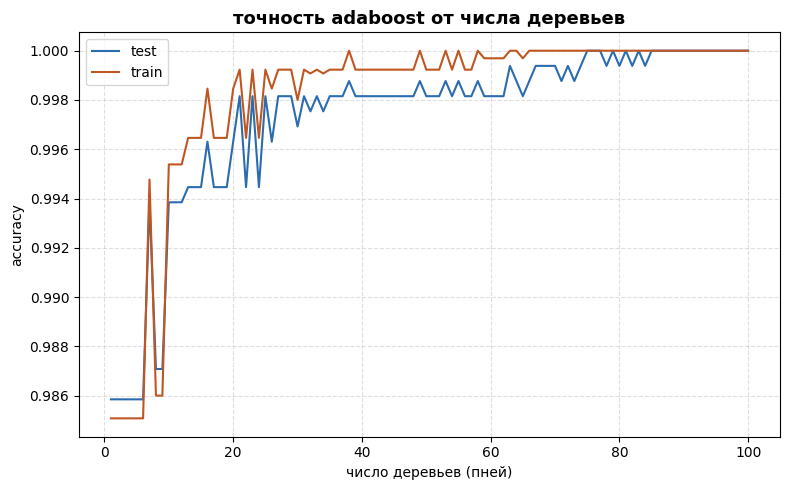

In [16]:
# построить график зависимости точности от количества деревьев
acc_test = (ada.staged_predict(X_test) == y_test.to_numpy()).mean(axis=1)
acc_train = (ada.staged_predict(X_train) == y_train.to_numpy()).mean(axis=1)
n_trees = range(1, len(ada.trees_) + 1)

plt.figure(figsize=(8, 5))
plt.plot(n_trees, acc_test, color='#2b6cb0', label='test')
plt.plot(n_trees, acc_train, color='#c05621', label='train')
plt.title('точность adaboost от числа деревьев', fontsize=13, fontweight='bold')
plt.xlabel('число деревьев (пней)')
plt.ylabel('accuracy')
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()

- первый пень задаёт один вопрос (про запах) и даёт accuracy 0.9858. у него самый большой вес голоса, поэтому первые 6 деревьев ответ не меняют
- дальше каждое новое дерево смотрит на объекты, на которых прошлые ошибались (их вес вырос), и исправляет часть ошибок -- accuracy растёт ступеньками: 0.9938 на 10 деревьях, 0.9982 на 50
- на train accuracy стала 1.0 на 38 деревьях и держится с 66-го, на test -- с 85-го
- колебания на графике -- новое дерево исправляет одни объекты и портит другие
- линии train и test идут рядом

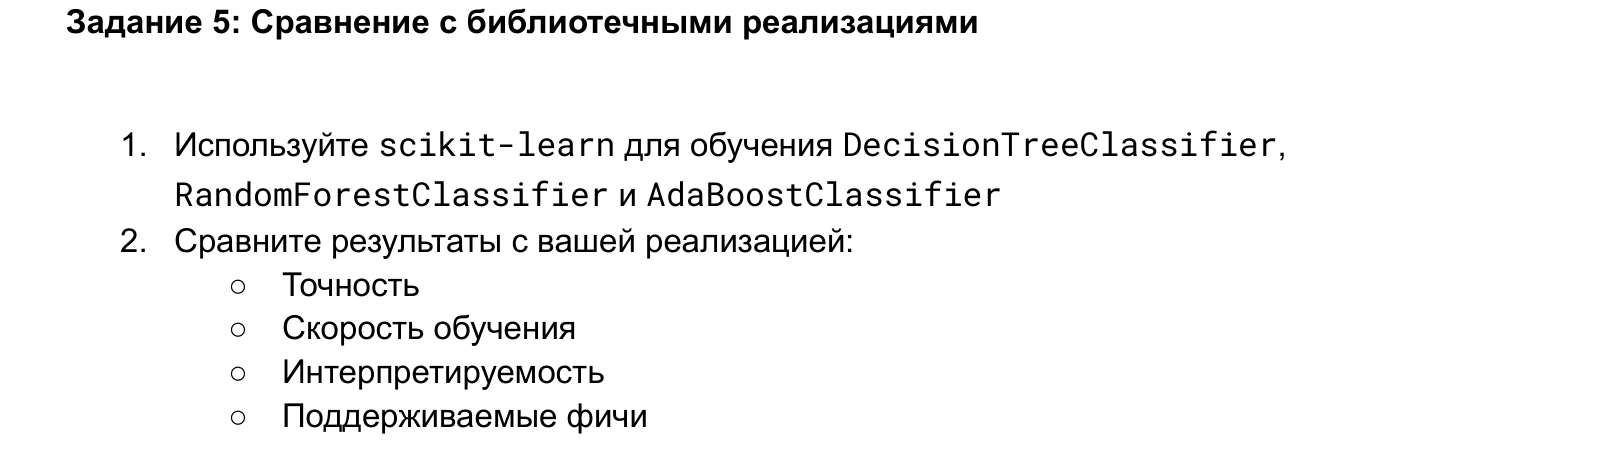

In [17]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

# используйте scikit-learn для обучения decisiontreeclassifier, randomforestclassifier и adaboostclassifier
# sklearn понимает только числа, поэтому буквы превращаем в столбцы из 0 и 1 (one-hot)
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X_train)
Z_train, Z_test = encoder.transform(X_train), encoder.transform(X_test)
print(Z_train.shape)  # 22 признака стали столбцами

sk_models = {
    'sklearn дерево': DecisionTreeClassifier(max_depth=4, random_state=42),
    'sklearn лес': RandomForestClassifier(n_estimators=100, max_depth=4, random_state=42),
    'sklearn adaboost': AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1), n_estimators=100, random_state=42),
}
sk_pred, sk_time = {}, {}
for name, model in sk_models.items():
    t0 = time.perf_counter()
    model.fit(Z_train, y_train)
    sk_time[name] = time.perf_counter() - t0
    sk_pred[name] = model.predict(Z_test)

(6499, 117)


In [18]:
from sklearn.preprocessing import OrdinalEncoder

# сравните результаты с вашей реализацией: поддерживаемые фичи
# проверяем, что принимает на вход каждая модель (результат попадёт в таблицы ниже)
def works(model, data):
    try:
        model.fit(data, y_train)
        return 'работает'
    except ValueError:
        return 'ошибка'

X_letters = X_train.drop(columns='stalk-root')   # буквы, без пропусков
X_nan = OrdinalEncoder().fit_transform(X_train)  # числа, но пропуски остались NaN

models_to_check = {
    'своё дерево': MyDecisionTree(max_depth=4),
    'свой лес': MyRandomForest(n_trees=3, max_depth=4),
    'свой adaboost': MyAdaBoost(n_estimators=3),
    'sklearn дерево': DecisionTreeClassifier(),
    'sklearn лес': RandomForestClassifier(),
    'sklearn adaboost': AdaBoostClassifier(),
}
support = pd.DataFrame({
    'буквы вместо чисел': [works(m, X_letters) for m in models_to_check.values()],
    'пропуски (NaN)': [works(m, X_train if name.startswith('сво') else X_nan) for name, m in models_to_check.items()],
}, index=models_to_check.keys())

In [19]:
# сравните результаты с вашей реализацией: решающее дерево (точность, скорость обучения, поддерживаемые фичи)
def compare_table(own_name, sk_name, own_pred, own_time):
    preds = [own_pred, sk_pred[sk_name]]
    table = pd.DataFrame({
        'accuracy': [accuracy_score(y_test, pred) for pred in preds],
        'ошибок': [int((y_test.to_numpy() != pred).sum()) for pred in preds],
        'время обучения, с': [own_time, sk_time[sk_name]],
    }, index=[own_name, sk_name])
    return table.join(support).round(4)  # join добавляет столбцы про поддерживаемые фичи

compare_table('своё дерево', 'sklearn дерево', tree_pred, tree_time)

,accuracy,ошибок,"время обучения, с",буквы вместо чисел,пропуски (NaN)
своё дерево,0.9963,6,0.0256,работает,работает
sklearn дерево,0.9914,14,0.0106,ошибка,работает


- точность: своё дерево 6 ошибок, sklearn 14. у sklearn после one-hot каждый вопрос про одно значение признака (`odor_n`), у нас про набор значений (`odor in [a, l, n]`), поэтому на тех же 4 уровнях наше дерево ошибается реже
- скорость: sklearn быстрее
- фичи: sklearn не принимает буквы (их надо переводить в числа), пропуски принимает. наше дерево принимает и буквы, и пропуски
- числовые признаки наша реализация не умеет: она делит только по значениям-категориям. sklearn умеет числа и больше двух классов

In [20]:
# сравните результаты с вашей реализацией: случайный лес (точность, скорость обучения, поддерживаемые фичи)
compare_table('свой лес', 'sklearn лес', forest_pred, forest_time)

,accuracy,ошибок,"время обучения, с",буквы вместо чисел,пропуски (NaN)
свой лес,0.9982,3,1.1117,работает,работает
sklearn лес,0.9914,14,0.0931,ошибка,работает


- точность: свой лес 3 ошибки, sklearn 14
- скорость: sklearn быстрее в 10 с лишним раз
- фичи: как у дерева -- sklearn буквы не принимает, пропуски принимает, наш лес принимает и то и другое

In [21]:
# сравните результаты с вашей реализацией: adaboost (точность, скорость обучения, поддерживаемые фичи)
compare_table('свой adaboost', 'sklearn adaboost', ada_pred, ada_time)

,accuracy,ошибок,"время обучения, с",буквы вместо чисел,пропуски (NaN)
свой adaboost,1.0000,0,1.0431,работает,работает
sklearn adaboost,0.9988,2,0.5130,ошибка,ошибка


- точность: свой adaboost 0 ошибок, sklearn 2
- скорость: sklearn быстрее примерно в 2 раза
- фичи: sklearn не принимает ни буквы, ни пропуски, наш принимает и то и другое

In [22]:
# сравните результаты с вашей реализацией: интерпретируемость (дерево в виде правил у sklearn)
print(export_text(sk_models['sklearn дерево'], feature_names=list(encoder.get_feature_names_out())))

|--- odor_n <= 0.50
|   |--- stalk-root_c <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- odor_a <= 0.50
|   |   |   |   |--- class: p
|   |   |   |--- odor_a >  0.50
|   |   |   |   |--- class: e
|   |   |--- stalk-surface-below-ring_y >  0.50
|   |   |   |--- class: e
|   |--- stalk-root_c >  0.50
|   |   |--- stalk-surface-above-ring_s <= 0.50
|   |   |   |--- class: p
|   |   |--- stalk-surface-above-ring_s >  0.50
|   |   |   |--- class: e
|--- odor_n >  0.50
|   |--- spore-print-color_r <= 0.50
|   |   |--- stalk-surface-below-ring_y <= 0.50
|   |   |   |--- cap-surface_g <= 0.50
|   |   |   |   |--- class: e
|   |   |   |--- cap-surface_g >  0.50
|   |   |   |   |--- class: p
|   |   |--- stalk-surface-below-ring_y >  0.50
|   |   |   |--- ring-number_t <= 0.50
|   |   |   |   |--- class: p
|   |   |   |--- ring-number_t >  0.50
|   |   |   |   |--- class: e
|   |--- spore-print-color_r >  0.50
|   |   |--- class: p



- дерево sklearn тоже читается как правила, но вопросы про столбцы из 0 и 1: `odor_n <= 0.50` значит "запах не равен `n`". у нашего дерева вопрос сразу про набор значений: `odor in [a, l, n]`
- лес и adaboost -- это 100 деревьев, глазами их не прочитать ни у нас, ни у sklearn
- у sklearn есть важность признаков (`feature_importances_`), у нашей реализации нет